# Experiment 2: Reproducing Dr Li's FPFLI (Xiao, Sapermsap, Chen and Li, Optica 2023)
**Forhad Islam.** Runs on my RTX 3090.

**FPFLI** makes fluorescence lifetime images from about **10 photons per pixel** with two networks:
* **LLE** (local lifetime estimator): one lifetime per 8 by 8 patch. Small: about 29,000 weights.
* **NIII** (neural implicit image interpolation): turns the blocky patch map into a sharp full size image, guided by the intensity image. Big: 14.6 million weights.

**What I do here:** run **his own code, trained models and sample data** (from the group's GitHub), then a first test of rounding the LLE weights to 8 and 4 bit.

**Main results (earlier run):** his results reproduce (about 0.13 ns error on real HEK293 cells); 8 bit barely changes anything; plain 4 bit breaks the network (1 to 2 ns errors).

In [1]:
import os, sys, glob, subprocess, warnings
warnings.filterwarnings("ignore")
HERE = os.getcwd()                                                       # this experiment's folder
BASE = HERE                                                          # find the University of Strathclyde folder (works at any depth)
while not os.path.isdir(os.path.join(BASE, "04_Shared_Code_and_Data")) and os.path.dirname(BASE) != BASE:
    BASE = os.path.dirname(BASE)
CODE = os.path.join(BASE, "04_Shared_Code_and_Data", "Dr_Li_FPFLI_code")  # Dr Li's FPFLI code, models and sample data
DATA = os.path.join(BASE, "04_Shared_Code_and_Data", "Datasets")
GLASGOW = os.path.join(DATA, "SPAD_FLIM_Glasgow_Zickus2020",
    "DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
try:
    import mat73
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "mat73"], check=True); import mat73
sys.path.insert(0, CODE); os.chdir(CODE)     # Dr Li's code uses paths like sample_data/... and ./model_parameters/...
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
print("results will be saved in:", HERE)

GPU: NVIDIA GeForce RTX 3090
results will be saved in: <project>\03_Experiments\E2_FPFLI_Reproduction


## The code

**What this code does** (from the script `reproduce_and_quantise.py`):

```
reproduce_and_quantise.py

Part 1: Reproduce Dr David Li's FPFLI results (Xiao, Sapermsap, Chen and Li, Optica 2023)
        using the group's own code, pretrained models and sample data.
Part 2: My extension. Quantise the local lifetime network (LLE) to INT8 and INT4
        and measure how much the final lifetime images change.

Run from inside the Evaluation folder:
    python reproduce_and_quantise.py
Results go to ./my_results
```

### Setup: imports and settings

In [2]:
import os, json, time, copy, warnings
import numpy as np
import torch
warnings.filterwarnings("ignore")

# newer PyTorch refuses to load older checkpoints unless weights_only is False
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})

import scipy.io as io
import mat73
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from Neural_implict_interploation import NIII_process

OUT = os.path.join(HERE, "my_results")
os.makedirs(OUT, exist_ok=True)
PATCH = 8


def mask_hist(hist, thres, strict):
    inten = hist.sum(2)
    keep = inten > thres if strict else inten >= thres
    hist = hist * keep[..., None]
    return hist, inten * keep


def run_fpfli(hist, irf, thres, strict, lle_path, quant_bits=None):
    hist_m, mask = mask_hist(hist.copy(), thres, strict)
    t0 = time.time()
    lr_tau = PLL.Pred_local_lifetime(hist_m, irf, scaling_ratio=PATCH, h=0.039, file_path=lle_path)
    if quant_bits:
        quantise_model(PLL.model, quant_bits)
    lr_tau = lr_tau.eval_local_tau()
    nii = prep_exp_data(mask, lr_tau).prep_data()
    pred = np.squeeze(NIII_process(nii, ratio=PATCH), (0, 1))
    pred[pred < 0] = 0
    return pred, mask, time.time() - t0, lr_tau

In [3]:
def quantise_model(model, bits):
    """Per output channel symmetric fake quantisation of every weight tensor."""
    qmax = 2 ** (bits - 1) - 1
    with torch.no_grad():
        for name, p in model.named_parameters():
            if p.dim() < 2:
                continue
            w = p.data
            flat = w.reshape(w.shape[0], -1)
            scale = flat.abs().max(1, keepdim=True).values.clamp(min=1e-12) / qmax
            q = torch.round(flat / scale).clamp(-qmax, qmax) * scale
            p.data.copy_(q.reshape(w.shape))


def mae(pred, gt, mask):
    m = (mask > 0) & (gt > 0)
    return float(np.mean(np.abs(pred[m] - gt[m])))


def show(imgs, titles, vmax, fname, vmin=0):
    fig, ax = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 4))
    for a, im, t in zip(ax, imgs, titles):
        h = a.imshow(im, cmap="inferno", vmin=vmin, vmax=vmax)
        a.set_title(t, fontsize=10); a.axis("off")
    fig.colorbar(h, ax=ax, shrink=0.8, label="lifetime (ns)")
    fig.savefig(os.path.join(OUT, fname), dpi=130, bbox_inches="tight"); plt.close(fig)


results = {}
irf_g = io.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
LLE_A = "./model_parameters/LLE_parameter.pth"
LLE_B = "./model_parameters/LLE_parameter_1_3ns.pth"

### Part 1a: low light synthetic FLIM images (ground truth known)

In [4]:
synth = {}
for s in ["1", "2", "3", "4", "5", "6"]:
    d = io.loadmat(f"sample_data/{s}.mat")
    hist = d["Hist"].astype("float32"); gt = d["tau_gt"].astype("float32")
    row = {"photons_per_pixel": float(hist.sum(2)[hist.sum(2) > 3].mean())}
    imgs = {}
    for bits in [None, 8, 4]:
        pred, mask, t, _ = run_fpfli(hist, irf_g, 3, True, LLE_A, bits)
        key = "FP32" if bits is None else f"INT{bits}"
        row[key + "_MAE_ns"] = mae(pred, gt, mask); row[key + "_seconds"] = t
        imgs[key] = pred
    row["INT8_vs_FP32_median_change_ns"] = float(np.median(np.abs(imgs["INT8"] - imgs["FP32"])[mask > 0]))
    row["INT4_vs_FP32_median_change_ns"] = float(np.median(np.abs(imgs["INT4"] - imgs["FP32"])[mask > 0]))
    synth[s] = row
    if s == "3":
        show([hist.sum(2), gt, imgs["FP32"], imgs["INT8"], imgs["INT4"]],
             ["Photon counts", "True lifetime", "FPFLI (FP32)", "FPFLI, LLE at INT8", "FPFLI, LLE at INT4"],
             4, "fig1_synthetic_sample3.png")
    print("sample", s, {k: round(v, 3) for k, v in row.items()})
results["synthetic_low_light"] = synth

Complete 'NIII_process' in 0.4664 secs
Complete 'NIII_process' in 0.1770 secs
Complete 'NIII_process' in 0.1754 secs
sample 1 {'photons_per_pixel': 11.24, 'FP32_MAE_ns': 0.085, 'FP32_seconds': 0.534, 'INT8_MAE_ns': 0.089, 'INT8_seconds': 0.229, 'INT4_MAE_ns': 1.072, 'INT4_seconds': 0.239, 'INT8_vs_FP32_median_change_ns': 0.021, 'INT4_vs_FP32_median_change_ns': 1.012}
Complete 'NIII_process' in 0.1849 secs
Complete 'NIII_process' in 0.1772 secs
Complete 'NIII_process' in 0.1776 secs
sample 2 {'photons_per_pixel': 12.564, 'FP32_MAE_ns': 0.119, 'FP32_seconds': 0.253, 'INT8_MAE_ns': 0.129, 'INT8_seconds': 0.241, 'INT4_MAE_ns': 1.624, 'INT4_seconds': 0.244, 'INT8_vs_FP32_median_change_ns': 0.024, 'INT4_vs_FP32_median_change_ns': 1.67}
Complete 'NIII_process' in 0.1711 secs
Complete 'NIII_process' in 0.1765 secs
Complete 'NIII_process' in 0.1713 secs
sample 3 {'photons_per_pixel': 12.314, 'FP32_MAE_ns': 0.088, 'FP32_seconds': 0.233, 'INT8_MAE_ns': 0.088, 'INT8_seconds': 0.246, 'INT4_MAE_ns':

### Part 1b: real HEK293 cells with gold nanorods

In [5]:
d = io.loadmat("sample_data/hek_low.mat")
hist = d["hist"].astype("float32"); irf = d["irf"].astype("float32")
gt = mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32")
hek = {}; imgs = {}
for bits in [None, 8, 4]:
    pred, mask, t, _ = run_fpfli(hist, irf, 3, True, LLE_B, bits)
    key = "FP32" if bits is None else f"INT{bits}"
    hek[key + "_MAE_ns"] = mae(pred, gt, mask); hek[key + "_seconds"] = t; imgs[key] = pred
show([gt, imgs["FP32"], imgs["INT8"], imgs["INT4"]],
     ["Reference (high photon)", "FPFLI from few photons", "LLE at INT8", "LLE at INT4"], 2.5, "fig2_hek293_real.png")
fig, a = plt.subplots(figsize=(5, 3.5))
b = np.arange(0.5, 3, 0.05)
a.hist(gt[mask > 0], b, alpha=.5, label="reference"); a.hist(imgs["FP32"][mask > 0], b, alpha=.5, label="FPFLI FP32")
a.hist(imgs["INT8"][mask > 0], b, histtype="step", lw=2, label="FPFLI INT8")
a.set_xlabel("lifetime (ns)"); a.set_ylabel("pixels"); a.legend()
fig.savefig(os.path.join(OUT, "fig3_hek293_histogram.png"), dpi=130, bbox_inches="tight"); plt.close(fig)
results["hek293_real"] = hek
print("HEK293", {k: round(v, 3) for k, v in hek.items()})

Complete 'NIII_process' in 0.2861 secs
Complete 'NIII_process' in 0.2482 secs
Complete 'NIII_process' in 0.1729 secs
HEK293 {'FP32_MAE_ns': 0.134, 'FP32_seconds': 0.372, 'INT8_MAE_ns': 0.161, 'INT8_seconds': 0.319, 'INT4_MAE_ns': 1.045, 'INT4_seconds': 0.228}


### Part 1c: real microspheres (no ground truth, two lifetimes should separate)

In [6]:
irf_m = mat73.loadmat("sample_data/irf_measure.mat")["irf"].astype("float32")
for name in ["microsphere_2p_1", "microsphere_2p_2"]:
    hist = mat73.loadmat(f"sample_data/{name}.mat")["Hist"].astype("float32")
    p32, mask, t, _ = run_fpfli(hist, irf_m, 4, False, LLE_A)
    p8, _, _, _ = run_fpfli(hist, irf_m, 4, False, LLE_A, 8)
    show([hist.sum(2), p32, p8], ["Photon counts", "FPFLI FP32", "FPFLI, LLE at INT8"], 4, f"fig4_{name}.png", vmin=1)
    results[name] = {"seconds": t, "INT8_vs_FP32_median_change_ns": float(np.median(np.abs(p8 - p32)[mask > 0]))}

json.dump(results, open(os.path.join(OUT, "results.json"), "w"), indent=2)
print("Saved to", OUT)

Complete 'NIII_process' in 0.1716 secs
Complete 'NIII_process' in 0.1730 secs
Complete 'NIII_process' in 0.1734 secs
Complete 'NIII_process' in 0.1664 secs
Saved to <project>\03_Experiments\E2_FPFLI_Reproduction\my_results


### Figures

fig1_synthetic_sample3.png


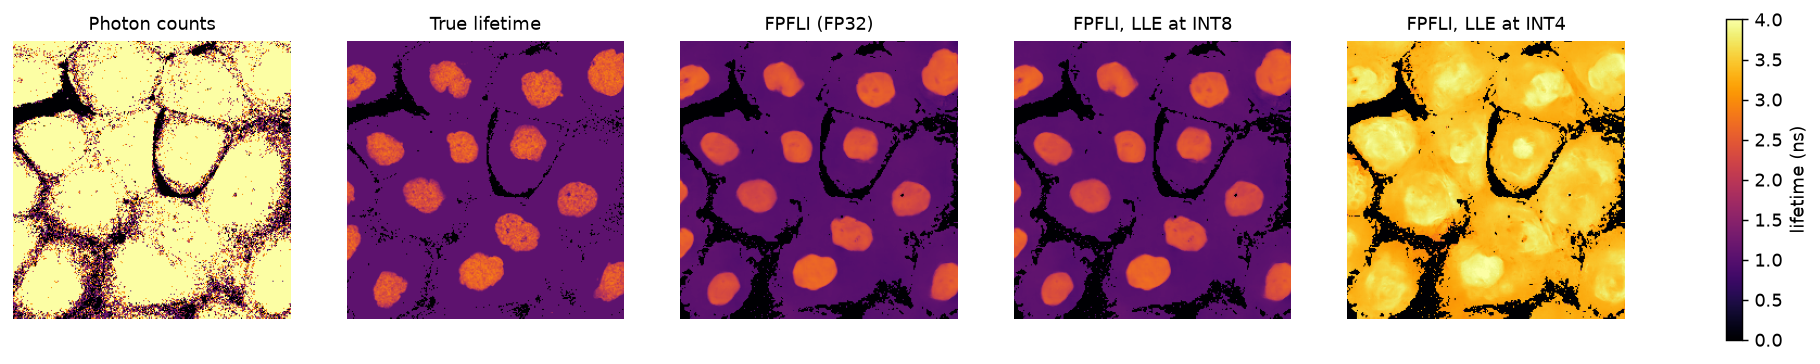

fig2_hek293_real.png


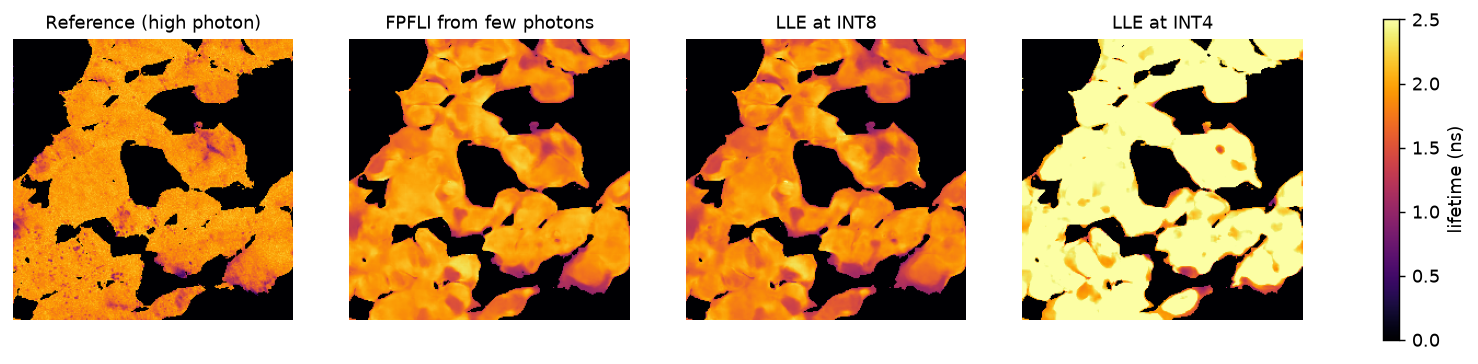

fig3_hek293_histogram.png


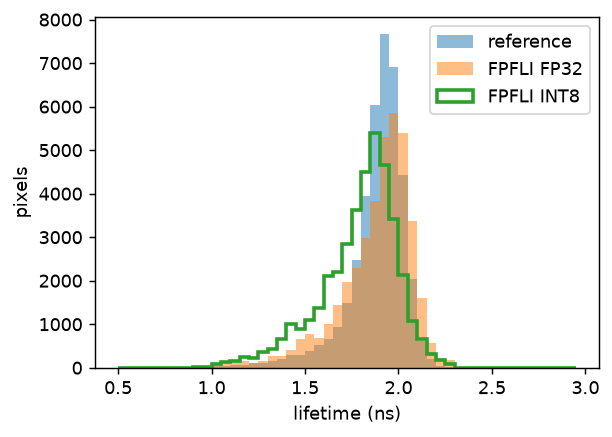

fig4_microsphere_2p_1.png


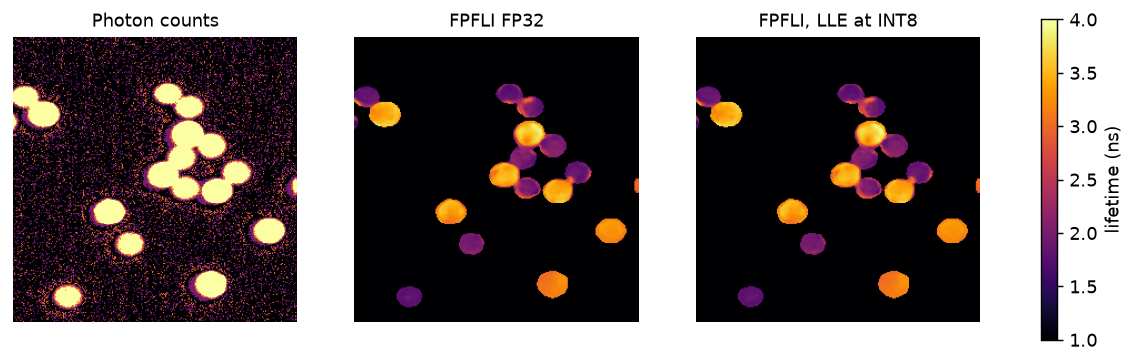

fig4_microsphere_2p_2.png


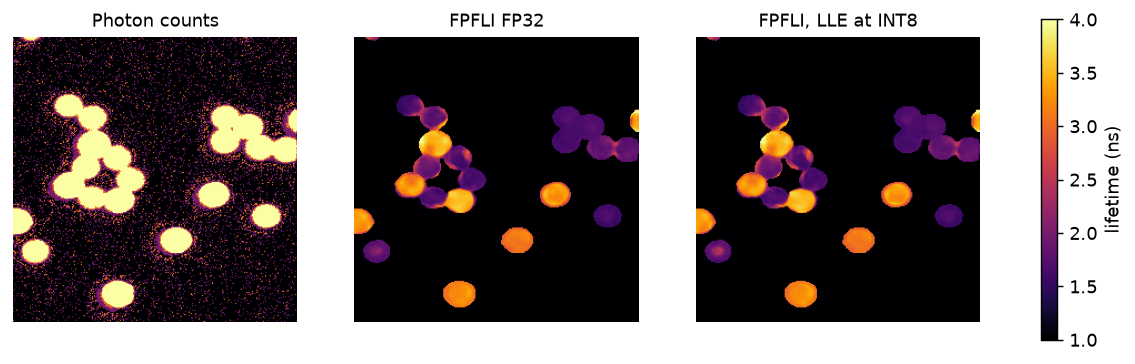

In [7]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))